# Practical 05 – Heart Disease Dataset Preprocessing and EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [2]:
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
path = Path('heart_disease.csv')
if not path.exists():
    pd.read_csv(url, header=None, names=columns, na_values='?').to_csv(path, index=False)
df = pd.read_csv(path, na_values='?')


In [3]:
for col in columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')


Shape: (303, 14) Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  241.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  275.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thala

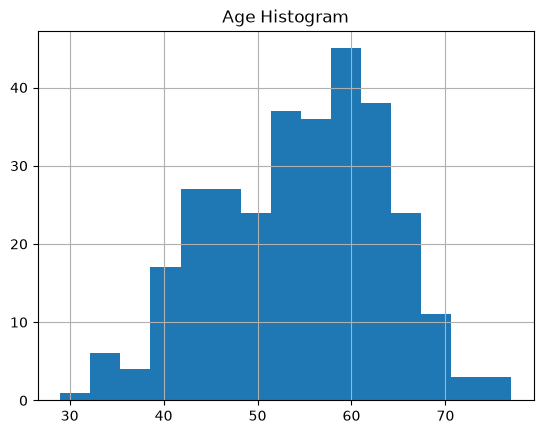

<Axes: >

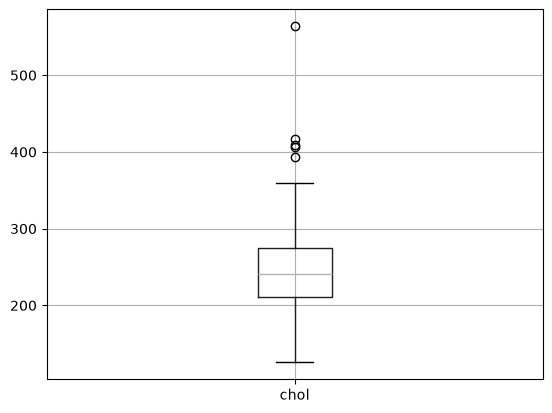

In [4]:
df['target'] = (df['target'] > 0).astype(int)
print('Shape:', df.shape, 'Missing values:\n', df.isna().sum())
print(df.describe())
df['age'].hist(bins=15)
plt.title('Age Histogram')
plt.show()
df.boxplot(column='chol')


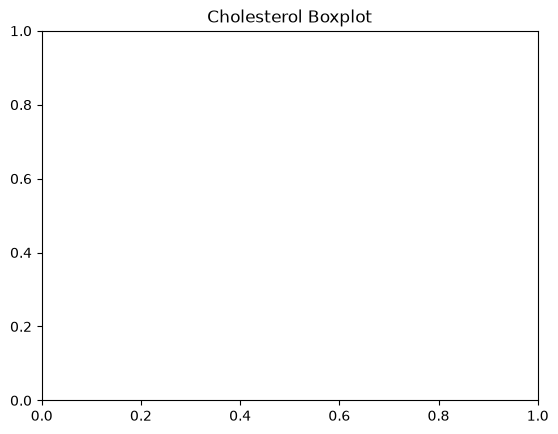

In [8]:
plt.title('Cholesterol Boxplot')
plt.show()
X = df.drop(columns='target')
y = df['target']
cat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
num = [c for c in X if c not in cat]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [7]:
prep = ColumnTransformer([('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num), ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))]), cat)])
print('Train:', prep.fit_transform(X_train).shape, 'Test:', prep.transform(X_test).shape)


Train: (242, 28) Test: (61, 28)
